In [1]:
!pip install -q datasets matplotlib pillow

In [2]:
import torch

print("PyTorch version:", torch.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from datasets import load_dataset

train_stream = load_dataset(
    "hassanjbara/AI4MARS",
    split="train",
    streaming = True
)

print("Dataset loaded successfully")

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

Dataset loaded successfully


In [4]:
sample = None

for row in train_stream:
  if row["has_labels"] and row["label_mask"] is not None:
    sample = row
    break

print("Available columns:", sample.keys())

print("Has labels:", sample["has_labels"])

print("Has masks:", sample["has_masks"])

Available columns: dict_keys(['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'])
Has labels: True
Has masks: True


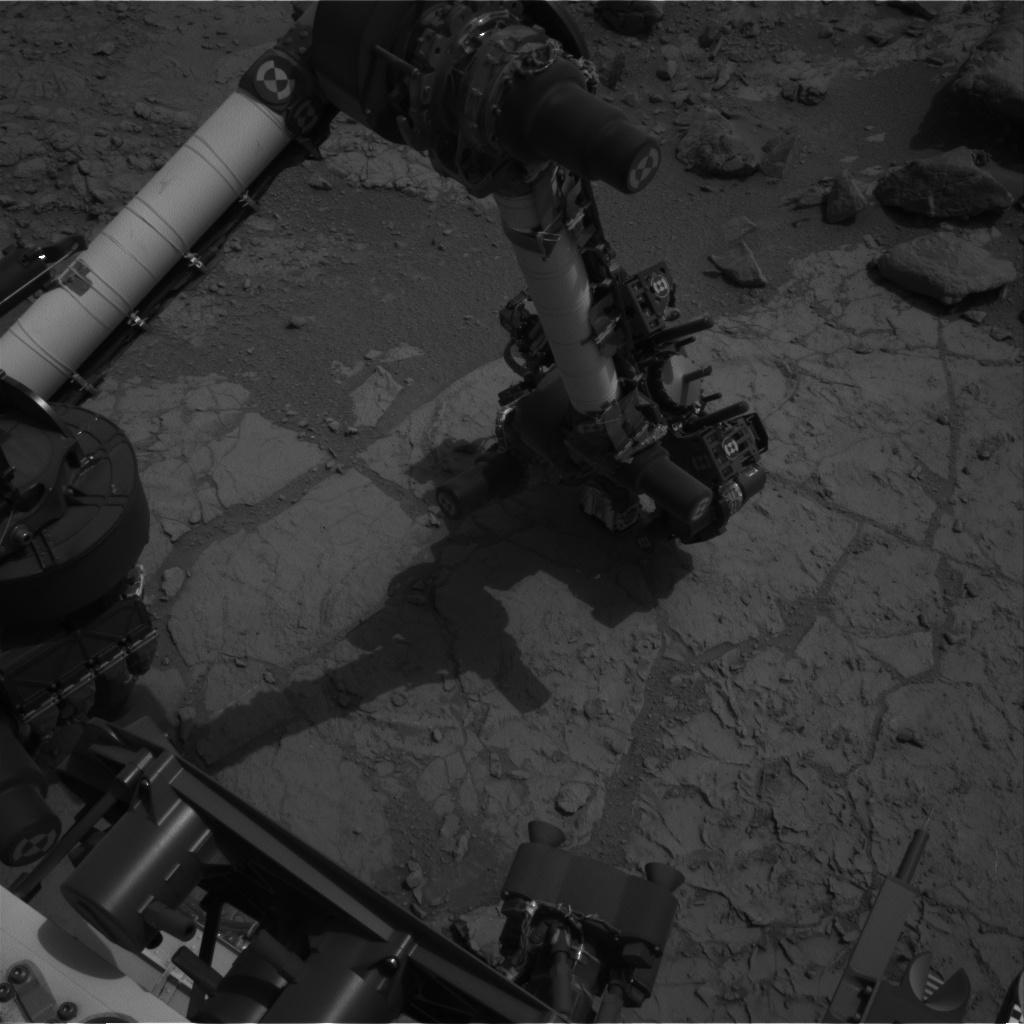

In [5]:
from IPython.display import display

display(sample["image"])

In [6]:
import numpy as np
from PIL import Image

mask = np.array(sample["label_mask"])

if mask.ndim == 3:
  mask = mask[..., 0]

print("Mask shape: ",mask.shape)
print("Unique pixel values: ",np.unique(mask))

Mask shape:  (1024, 1024)
Unique pixel values:  [  0   1   3 255]


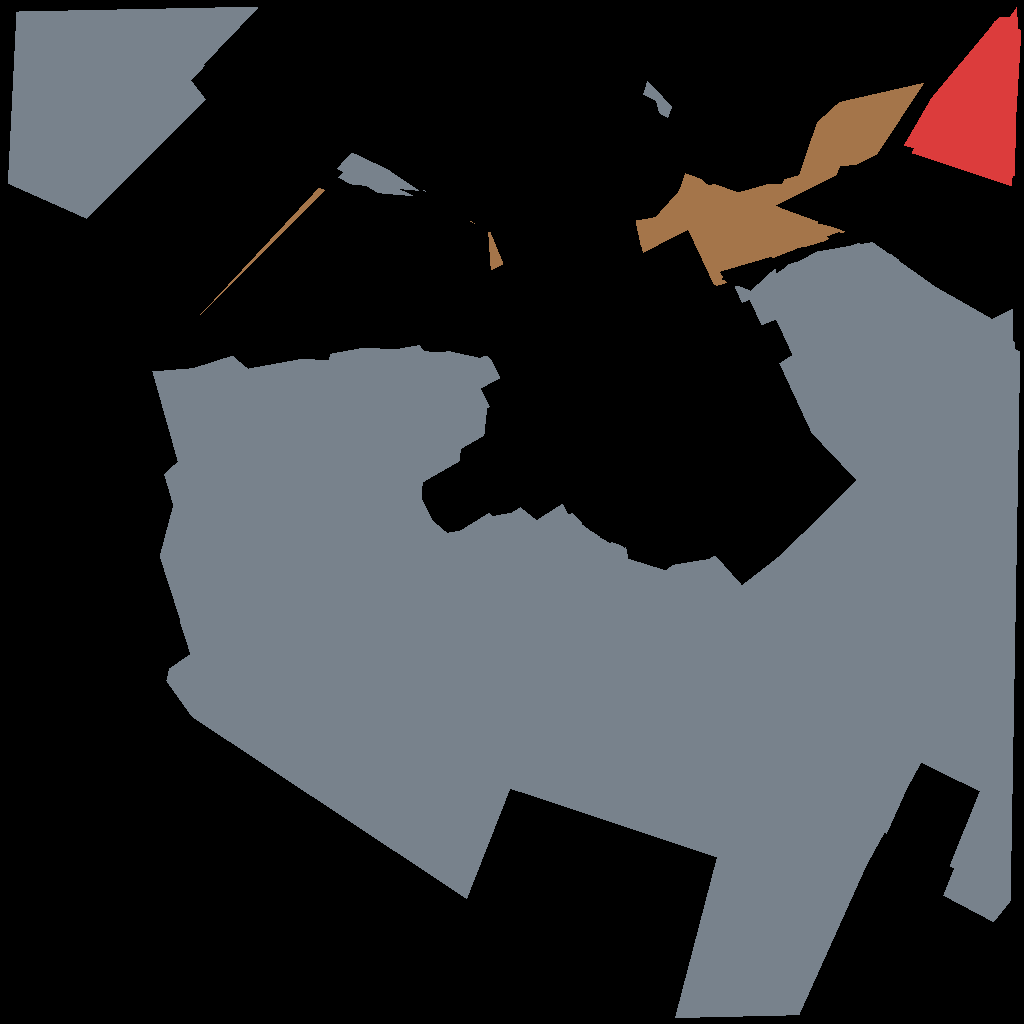

In [7]:
colors = np.array([
    [164,117,74], #Soil
    [120,130,140],  #Bedrock
    [238,190,70], #Sand
    [220,60,60] #Big Rock
],dtype=np.uint8)

colored_mask = np.zeros(
    (mask.shape[0],mask.shape[1],3),
    dtype=np.uint8
)

for class_id in range(4):
  colored_mask[mask == class_id] = colors[class_id]
colored_mask[mask==255] = [0,0,0]
display(Image.fromarray(colored_mask))

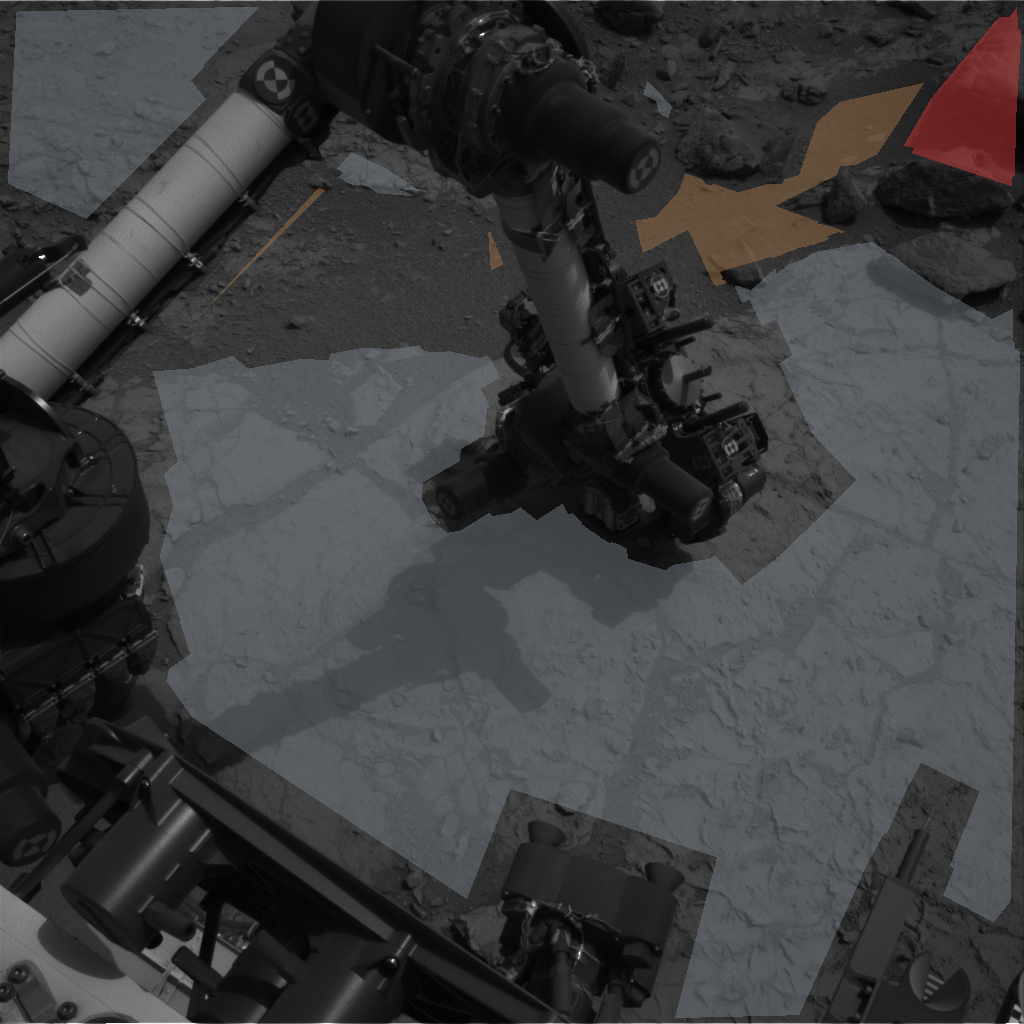

In [8]:
image = np.array(sample["image"].convert("RGB"))

valid = mask != 255

overlay = image.copy()

overlay[valid] = (
    0.55 * image[valid] +
    0.45 * colored_mask[valid]
).astype(np.uint8)

display(Image.fromarray(overlay))

In [9]:
values,counts = np.unique(
    mask,
    return_counts=True
)
class_names = {
    0: "Soil",
    1: "Bedrock",
    2: "Sand",
    3: "Big Rock",
    255: "Unlabelled"
}

total_pixels = mask.size

print("Total pixels:", total_pixels)
print("\nPixel distribution:\n")

for value, count in zip(values,counts):
  percentage = (count/total_pixels)*100

  print(
      f"{class_names[value]:12s} | "
      f"Pixels: {count:8d} | "
      f"Percentage: {percentage:.2f}%"
  )


Total pixels: 1048576

Pixel distribution:

Soil         | Pixels:    17993 | Percentage: 1.72%
Bedrock      | Pixels:   408609 | Percentage: 38.97%
Big Rock     | Pixels:    11645 | Percentage: 1.11%
Unlabelled   | Pixels:   610329 | Percentage: 58.21%


In [13]:
import numpy as np

for key in ("rover_mask","range_mask"):

  current_mask = sample[key]

  print("\nMask name:",key)

  if current_mask is None:
    print("Mask is missing")
    continue

  mask_array = np.array(current_mask)

  print("Original shape:",mask_array.shape)
  print("Data type:",mask_array.dtype)

  if mask_array.ndim == 3:
        mask_array = mask_array[..., 0]

  print("Processed shape:", mask_array.shape)

  values, counts = np.unique(
        mask_array,
        return_counts=True
    )

  print("Unique values:", values)

  print("Pixel counts:", counts)

  print(
        "Percentage of pixels to ignore:",
        round(np.mean(mask_array > 0) * 100, 2),
        "%"
    )


Mask name: rover_mask
Original shape: (1024, 1024)
Data type: uint8
Processed shape: (1024, 1024)
Unique values: [0 1]
Pixel counts: [559642 488934]
Percentage of pixels to ignore: 46.63 %

Mask name: range_mask
Original shape: (1024, 1024)
Data type: uint8
Processed shape: (1024, 1024)
Unique values: [0]
Pixel counts: [1048576]
Percentage of pixels to ignore: 0.0 %


ROVER MASK


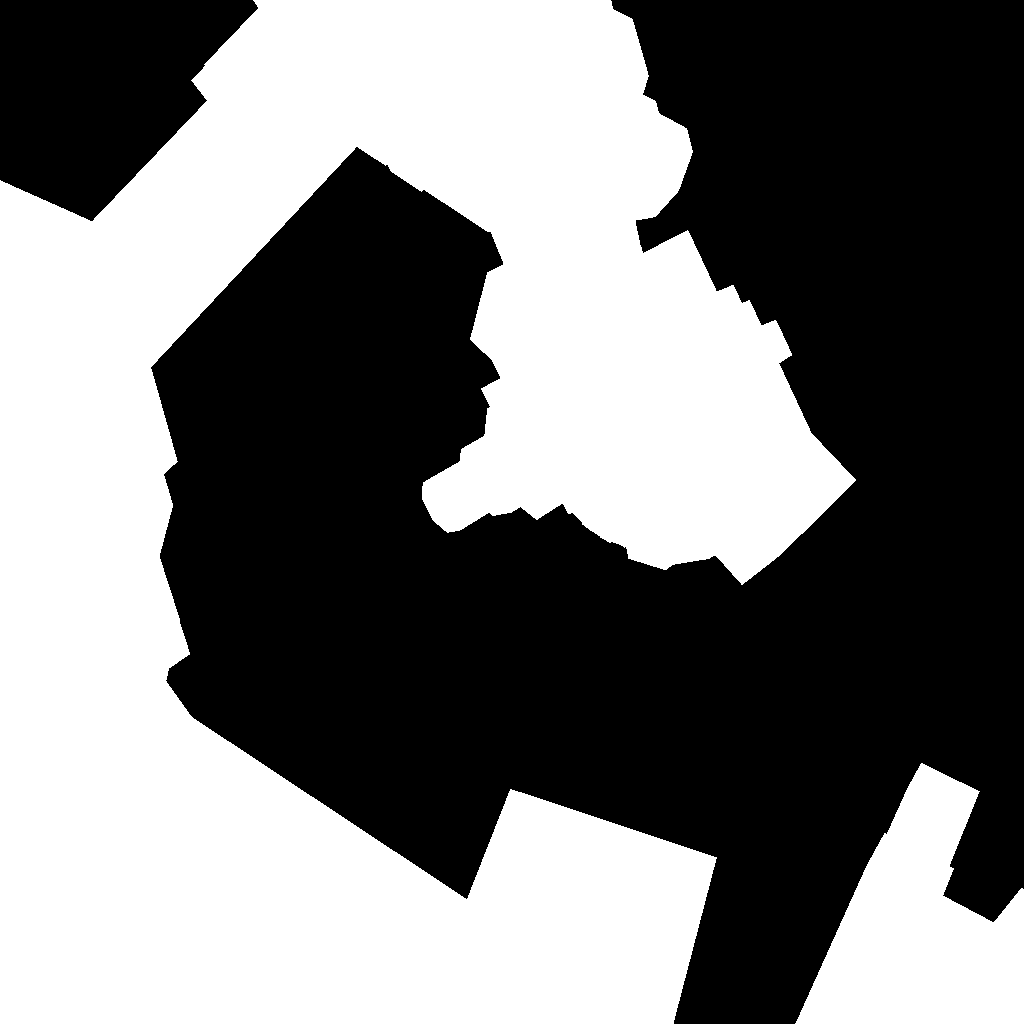

RANGE MASK


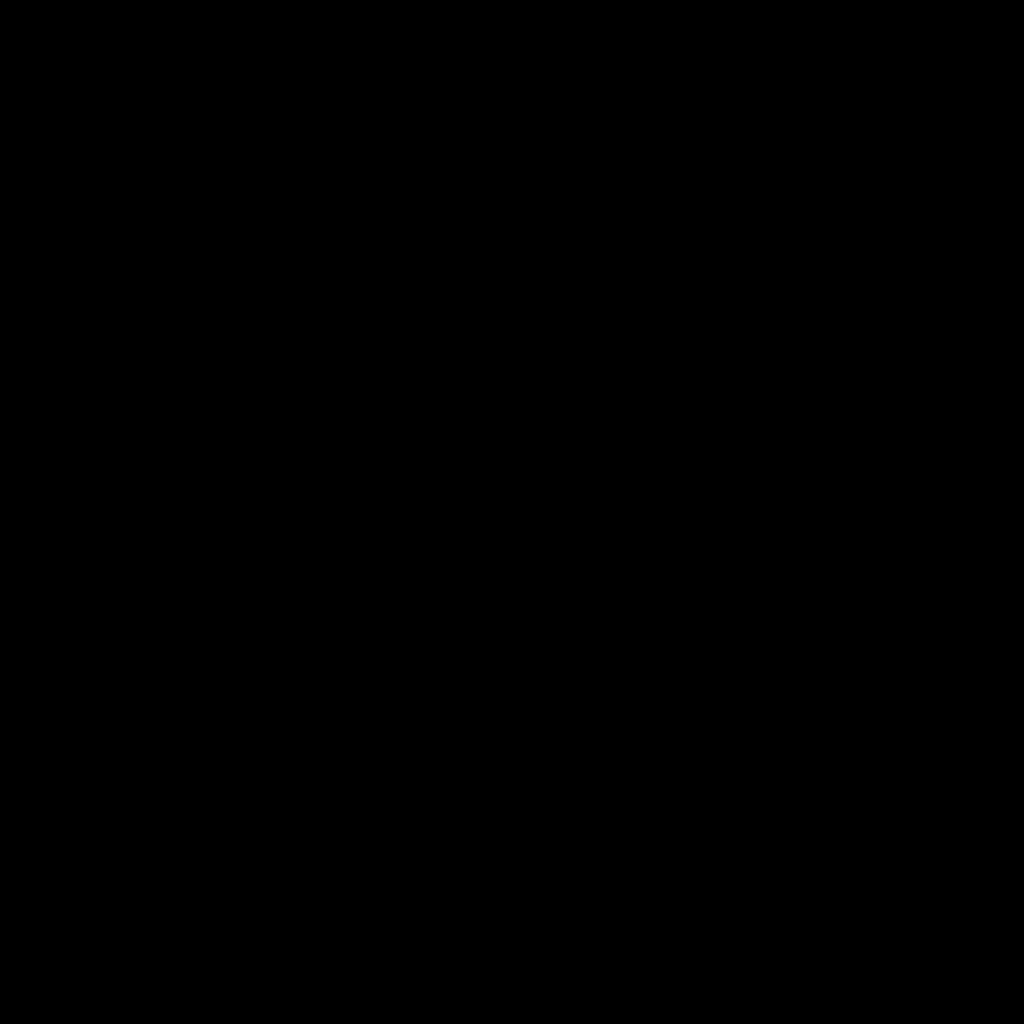

In [14]:
from PIL import Image
import numpy as np

rover_mask = np.array(sample["rover_mask"])

range_mask = np.array(sample["range_mask"])

print("ROVER MASK")

display(
    Image.fromarray(
        (rover_mask * 255).astype(np.uint8)
    )
)

print("RANGE MASK")

display(
    Image.fromarray(
        (range_mask * 255).astype(np.uint8)
    )
)

In [15]:
label = np.array(sample["label_mask"])

if label.ndim == 3:
    label = label[..., 0]

rover_ignore = rover_mask > 0
range_ignore = range_mask > 0

valid_before = label != 255

rover_affected = np.sum(
    valid_before & rover_ignore
)

range_affected = np.sum(
    valid_before & range_ignore
)

print("Labelled pixels before preprocessing:",
      np.sum(valid_before))

print("Labelled pixels inside rover region:",
      rover_affected)

print("Labelled pixels inside range region:",
      range_affected)

Labelled pixels before preprocessing: 438247
Labelled pixels inside rover region: 0
Labelled pixels inside range region: 0


In [16]:
import numpy as np

IGNORE = 255

def prepare(row):

    image = np.array(
        row["image"].convert("RGB")
    )

    label = np.array(row["label_mask"])

    if label.ndim == 3:
        label = label[..., 0]

    label = label.astype(np.int64, copy=True)

    if image.shape[:2] != label.shape:
        raise ValueError("Image and label dimensions do not match")

    for key in ("rover_mask", "range_mask"):

        if row[key] is not None:

            mask = np.array(row[key])

            if mask.ndim == 3:
                mask = mask[..., 0]

            if mask.shape != label.shape:
                raise ValueError(f"{key} dimensions do not match label")

            label[mask > 0] = IGNORE

    return image, label

In [17]:
processed_image, processed_label = prepare(sample)

print("IMAGE INFORMATION")

print("Shape:", processed_image.shape)
print("Data type:", processed_image.dtype)

print("\nLABEL INFORMATION")

print("Shape:", processed_label.shape)
print("Data type:", processed_label.dtype)

print("Unique values:", np.unique(processed_label))

print("\nPIXEL COUNTS")

values, counts = np.unique(
    processed_label,
    return_counts=True
)

for value, count in zip(values, counts):

    print(f"Class {value}: {count} pixels")

IMAGE INFORMATION
Shape: (1024, 1024, 3)
Data type: uint8

LABEL INFORMATION
Shape: (1024, 1024)
Data type: int64
Unique values: [  0   1   3 255]

PIXEL COUNTS
Class 0: 17993 pixels
Class 1: 408609 pixels
Class 3: 11645 pixels
Class 255: 610329 pixels


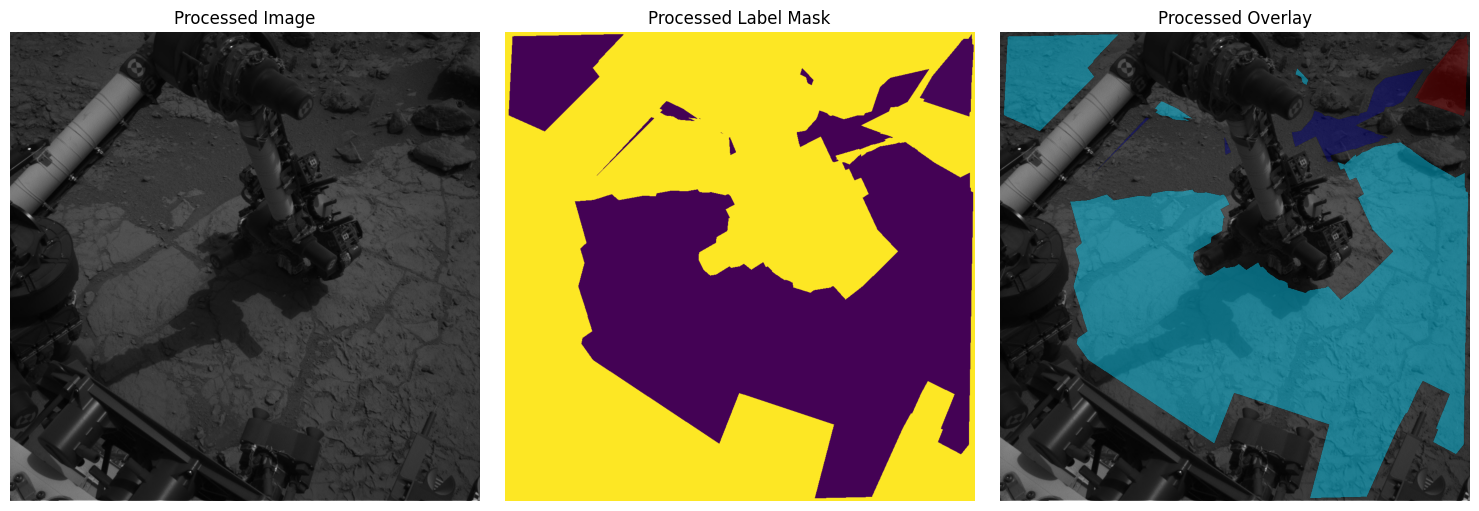

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(processed_image)
plt.title("Processed Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(processed_label)
plt.title("Processed Label Mask")
plt.axis("off")

plt.subplot(1, 3, 3)

plt.imshow(processed_image)
plt.imshow(
    np.ma.masked_where(
        processed_label == IGNORE,
        processed_label
    ),
    alpha=0.45,
    cmap="jet",
    vmin=0,
    vmax=3
)

plt.title("Processed Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
from PIL import Image
import numpy as np

toy_row = {

    "image": Image.fromarray(
        np.zeros((2, 3, 3), dtype=np.uint8)
    ),

    "label_mask": np.array([
        [0, 1, 2],
        [3, 255, 0]
    ], dtype=np.uint8),

    "rover_mask": np.array([
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.uint8),

    "range_mask": np.array([
        [0, 0, 0],
        [1, 0, 0]
    ], dtype=np.uint8)
}

In [20]:
toy_image, toy_label = prepare(toy_row)

print("Original label:")
print(toy_row["label_mask"])

print("\nProcessed label:")
print(toy_label)

Original label:
[[  0   1   2]
 [  3 255   0]]

Processed label:
[[  0 255   2]
 [255 255   0]]


In [21]:
expected = np.array([
    [0, 255, 2],
    [255, 255, 0]
], dtype=np.int64)

assert np.array_equal(toy_label, expected)

assert toy_image.shape == (2, 3, 3)

assert toy_label.dtype == np.int64

print("All preprocessing tests passed!")

All preprocessing tests passed!
